# Ekstrak dan Analisis CPU PlanetLab

Notebook ini mengekstrak seluruh trace dari `data/planetlab/planetlab_traces.zip`, memuat tiap folder tanggal, lalu membandingkan distribusi CPU dan overload. Overload didefinisikan sebagai utilisasi CPU **lebih dari 80%**.

## 1. Ekstrak semua data

Jalankan dari folder workspace yang berisi direktori `data/planetlab`. File diekstrak ke subfolder tanggal masing-masing.

In [2]:
from pathlib import Path, PurePosixPath
import re
import shutil
import zipfile

DATA_DIR = Path.cwd() / "data" / "planetlab"
ZIP_PATH = DATA_DIR / "planetlab_traces.zip"
DATA_DIR.mkdir(parents=True, exist_ok=True)

if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Arsip dataset tidak ditemukan: {ZIP_PATH.resolve()}")

daily_members = {}
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    for member in archive.infolist():
        if member.is_dir():
            continue

        parts = PurePosixPath(member.filename).parts
        day_index = next(
            (i for i, part in enumerate(parts) if re.fullmatch(r"\d{8}", part)),
            None,
        )
        if day_index is None or day_index + 1 >= len(parts):
            continue

        day = parts[day_index]
        relative_parts = parts[day_index + 1:]
        if any(part in ("", ".", "..") for part in relative_parts):
            raise ValueError(f"Path tidak aman di dalam ZIP: {member.filename}")
        daily_members.setdefault(day, []).append((member, relative_parts))

    if not daily_members:
        raise ValueError("Tidak ada folder trace bertanggal YYYYMMDD di dalam ZIP.")

    for day, members in sorted(daily_members.items()):
        day_dir = DATA_DIR / day
        day_dir.mkdir(parents=True, exist_ok=True)
        for member, relative_parts in members:
            output_path = day_dir.joinpath(*relative_parts)
            output_path.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(member, "r") as source, output_path.open("wb") as target:
                shutil.copyfileobj(source, target)

available_days = sorted(daily_members)
extracted_files = sum(len(members) for members in daily_members.values())
print(f"Folder tanggal: {len(available_days)}")
print(f"File trace diekstrak: {extracted_files}")
print("Tanggal:", ", ".join(available_days))
print("Lokasi:", DATA_DIR.resolve())

Folder tanggal: 10
File trace diekstrak: 11746
Tanggal: 20110303, 20110306, 20110309, 20110322, 20110325, 20110403, 20110409, 20110411, 20110412, 20110420
Lokasi: E:\.TEMPORARY\Project STMH\data\planetlab


## 2. Muat seluruh folder dan samakan skala CPU

Setiap file berisi satu trace VM. Trace yang lebih pendek diisi `NaN` di bagian akhir agar tidak dianggap sebagai utilisasi nol.

In [7]:
import numpy as np
import pandas as pd

def load_planetlab_day(folder, day):
    vm_traces = {}
    invalid_files = []

    for file_path in sorted(Path(folder).rglob("*")):
        if not file_path.is_file():
            continue
        try:
            values = np.asarray(np.loadtxt(file_path, dtype=float, ndmin=1)).ravel()
        except (OSError, ValueError) as error:
            invalid_files.append((file_path, str(error)))
            continue

        if values.size == 0 or not np.isfinite(values).all():
            invalid_files.append((file_path, "trace kosong atau berisi nilai non-finite"))
            continue
        vm_traces[file_path.relative_to(folder).as_posix()] = values

    if not vm_traces:
        raise ValueError(f"Tidak ada trace VM valid di folder {day}.")
    if invalid_files:
        examples = ", ".join(str(path.name) for path, _ in invalid_files[:5])
        print(f"PERINGATAN {day}: {len(invalid_files)} file tidak valid; contoh: {examples}")

    max_length = max(len(values) for values in vm_traces.values())
    workload = pd.DataFrame({
        vm: np.pad(values, (0, max_length - len(values)), constant_values=np.nan)
        for vm, values in vm_traces.items()
    })
    start_time = pd.Timestamp(
        year=int(day[:4]), month=int(day[4:6]), day=int(day[6:8])
    )
    workload.index = pd.date_range(start=start_time, periods=max_length, freq="5min")
    workload.index.name = "timestamp"
    print(f"{day}: {len(vm_traces)} VM, {max_length} sampel per trace terpanjang")
    return workload

df_by_day = {
    day: load_planetlab_day(DATA_DIR / day, day)
    for day in available_days
}

# Data PlanetLab dapat tersimpan sebagai rasio 0-1 atau persen 0-100.
global_min = min(float(frame.min().min()) for frame in df_by_day.values())
global_max = max(float(frame.max().max()) for frame in df_by_day.values())
if global_min < 0:
    raise ValueError(f"Nilai CPU negatif tidak valid: minimum {global_min}.")
if global_max <= 1.5:
    cpu_scale = "rasio 0-1"
elif global_max <= 100.5:
    cpu_scale = "persen 0-100, dikonversi ke rasio 0-1"
    df_by_day = {day: frame / 100.0 for day, frame in df_by_day.items()}
else:
    raise ValueError(f"Skala CPU tidak dikenali: nilai maksimum {global_max}.")

CPU_OVERLOAD_THRESHOLD = 0.80
print(f"Skala CPU: {cpu_scale}; ambang overload: >{CPU_OVERLOAD_THRESHOLD:.0%}")
print(f"Total trace VM: {sum(frame.shape[1] for frame in df_by_day.values()):,}")

20110303: 1052 VM, 288 sampel per trace terpanjang
20110306: 898 VM, 288 sampel per trace terpanjang
20110309: 1061 VM, 288 sampel per trace terpanjang
20110322: 1516 VM, 288 sampel per trace terpanjang
20110325: 1078 VM, 288 sampel per trace terpanjang
20110403: 1463 VM, 288 sampel per trace terpanjang
20110409: 1358 VM, 288 sampel per trace terpanjang
20110411: 1233 VM, 288 sampel per trace terpanjang
20110412: 1054 VM, 288 sampel per trace terpanjang
20110420: 1033 VM, 288 sampel per trace terpanjang
Skala CPU: persen 0-100, dikonversi ke rasio 0-1; ambang overload: >80%
Total trace VM: 11,746


## 3. Bandingkan overload dan distribusi CPU

Overload berarti utilisasi **>80%** (bukan >=80%). Metrik utama adalah jumlah dan persentase VM yang pernah melewati ambang tersebut setidaknya sekali. Persentase VM dipakai untuk perbandingan yang adil karena jumlah VM berbeda antar folder. Metrik pendamping, persentase sampel di atas 80%, menunjukkan seberapa sering overload terjadi sepanjang waktu. Keduanya dipisahkan dalam grafik agar skala metrik yang berbeda tidak menutupi hasil.

Ringkasan per folder (diurutkan dari proporsi VM overload tertinggi):


,folder,jumlah_vm,jumlah_observasi,sampel_cpu_di_atas_80,persen_sampel_overload,jumlah_vm_overload,persen_vm_overload,median_cpu_pct,p95_cpu_pct,maks_cpu_pct
0,20110420,1033,297504,2228,0.75,280,27.11,4.0,44.0,99.0
1,20110303,1052,302976,2723,0.90,221,21.01,6.0,50.0,99.0
2,20110411,1233,355104,2267,0.64,257,20.84,6.0,43.0,99.0
3,20110412,1054,303552,1958,0.65,207,19.64,6.0,43.0,99.0
4,20110409,1358,391104,2772,0.71,251,18.48,5.0,42.0,99.0
5,20110309,1061,305568,2334,0.76,193,18.19,4.0,42.0,99.0
6,20110403,1463,421344,4864,1.15,261,17.84,6.0,47.0,99.0
7,20110306,898,258624,2263,0.88,158,17.59,5.0,48.0,99.0
8,20110325,1078,310464,1950,0.63,181,16.79,6.0,39.0,99.0
9,20110322,1516,436608,1758,0.40,183,12.07,5.0,34.0,99.0


Folder dengan VM overload terbanyak: 20110420 — 280 dari 1033 VM (27.11%) pernah memiliki CPU >80%.
Tiga VM dengan sampel CPU >80% terbanyak di setiap folder:


,folder,vm,sampel_cpu_di_atas_80,jumlah_observasi,persen_sampel_overload
0,20110303,ttu2-1_nodes_planet-lab_org_nus_proxaudio,288,288,100.00
1,20110303,planetlab2_ecs_vuw_ac_nz_ucr_slice2,264,288,91.67
2,20110303,ricepl-5_cs_rice_edu_yale_p4p,240,288,83.33
3,20110306,ttu2-1_nodes_planet-lab_org_nus_proxaudio,288,288,100.00
4,20110306,planetlab-2_elisa_cpsc_ucalgary_ca_ucr_slice2,285,288,98.96
5,20110306,planetlab-5_eecs_cwru_edu_princeton_codeen,259,288,89.93
6,20110309,planet12_csc_ncsu_edu_ucr_slice2,279,288,96.88
7,20110309,planetlab10_millennium_berkeley_edu_usf_mobius_dm,266,288,92.36
8,20110309,plink_cs_uwaterloo_ca_yale_p4p,220,288,76.39
9,20110322,planetlab3_csail_mit_edu_uofathens_zoi,193,288,67.01


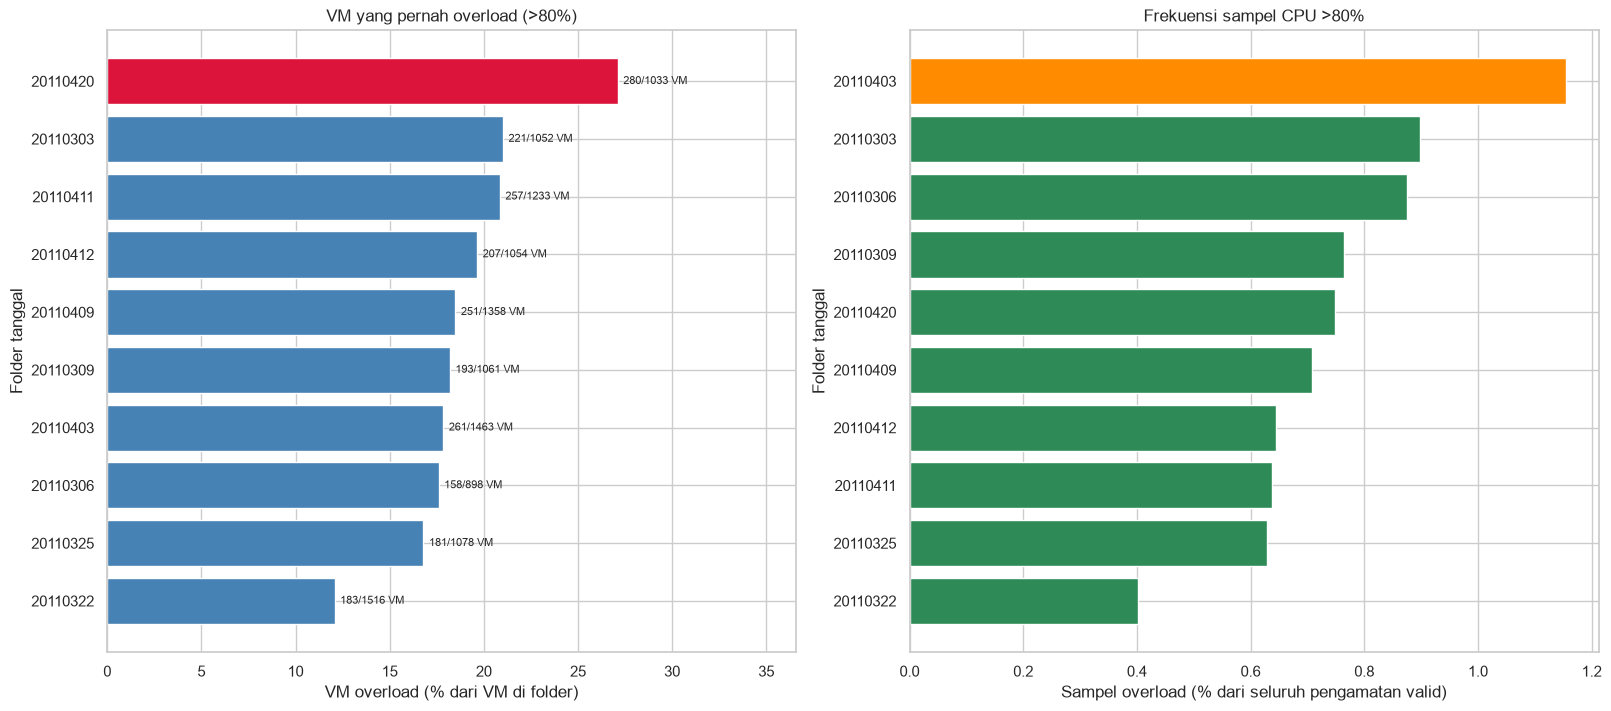

In [8]:
import matplotlib.pyplot as plt

folder_summary_rows = []
vm_overload_rows = []

for day in available_days:
    daily_df = df_by_day[day]
    values = daily_df.to_numpy(dtype=float)
    valid_mask = np.isfinite(values)
    overload_mask = valid_mask & (values > CPU_OVERLOAD_THRESHOLD)
    valid_counts_by_vm = valid_mask.sum(axis=0)
    overload_counts_by_vm = overload_mask.sum(axis=0)
    valid_count = int(valid_mask.sum())
    overload_count = int(overload_mask.sum())
    valid_values = values[valid_mask]
    overloaded_vm_mask = overload_counts_by_vm > 0

    folder_summary_rows.append({
        "folder": day,
        "jumlah_vm": len(daily_df.columns),
        "jumlah_observasi": valid_count,
        "sampel_cpu_di_atas_80": overload_count,
        "persen_sampel_overload": 100 * overload_count / valid_count,
        "jumlah_vm_overload": int(overloaded_vm_mask.sum()),
        "persen_vm_overload": 100 * overloaded_vm_mask.mean(),
        "median_cpu_pct": 100 * np.median(valid_values),
        "p95_cpu_pct": 100 * np.percentile(valid_values, 95),
        "maks_cpu_pct": 100 * np.max(valid_values),
    })

    for vm_index, vm_name in enumerate(daily_df.columns):
        overload_count_vm = int(overload_counts_by_vm[vm_index])
        if overload_count_vm > 0:
            valid_count_vm = int(valid_counts_by_vm[vm_index])
            vm_overload_rows.append({
                "folder": day,
                "vm": vm_name,
                "sampel_cpu_di_atas_80": overload_count_vm,
                "jumlah_observasi": valid_count_vm,
                "persen_sampel_overload": 100 * overload_count_vm / valid_count_vm,
            })

folder_summary = pd.DataFrame(folder_summary_rows).sort_values(
    ["persen_vm_overload", "persen_sampel_overload"],
    ascending=False,
).reset_index(drop=True)
vm_overload_detail = pd.DataFrame(vm_overload_rows)

print("Ringkasan per folder (diurutkan dari proporsi VM overload tertinggi):")
display(folder_summary.round(2))

top_folder = folder_summary.iloc[0]
print(
    f"Folder dengan VM overload terbanyak: {top_folder['folder']} — "
    f"{int(top_folder['jumlah_vm_overload'])} dari {int(top_folder['jumlah_vm'])} VM "
    f"({top_folder['persen_vm_overload']:.2f}%) pernah memiliki CPU >80%."
)

print("Tiga VM dengan sampel CPU >80% terbanyak di setiap folder:")
if vm_overload_detail.empty:
    print("Tidak ada sampel CPU di atas 80% pada seluruh folder.")
else:
    top_overloaded_vms = (
        vm_overload_detail.sort_values(
            ["folder", "sampel_cpu_di_atas_80"],
            ascending=[True, False],
        )
        .groupby("folder", sort=False)
        .head(3)
        .reset_index(drop=True)
    )
    display(top_overloaded_vms.round(2))

days = sorted(df_by_day)
cpu_distributions = []
for day in days:
    values = df_by_day[day].to_numpy(dtype=float)
    cpu_distributions.append(values[np.isfinite(values)] * 100)

plot_summary = folder_summary.sort_values("persen_vm_overload", ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)

bar_colors = [
    "crimson" if day == top_folder["folder"] else "steelblue"
    for day in plot_summary["folder"]
]
bars = axes[0].barh(
    plot_summary["folder"],
    plot_summary["persen_vm_overload"],
    color=bar_colors,
)
for bar, (_, row) in zip(bars, plot_summary.iterrows()):
    axes[0].text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{int(row['jumlah_vm_overload'])}/{int(row['jumlah_vm'])} VM",
        va="center",
        fontsize=8,
    )
axes[0].set_title("VM yang pernah overload (>80%)")
axes[0].set_xlabel("VM overload (% dari VM di folder)")
axes[0].set_ylabel("Folder tanggal")
axes[0].set_xlim(0, plot_summary["persen_vm_overload"].max() * 1.35)

sample_plot = folder_summary.sort_values("persen_sampel_overload", ascending=True)
sample_top_folder = folder_summary.loc[
    folder_summary["persen_sampel_overload"].idxmax(), "folder"
]
sample_colors = [
    "darkorange" if day == sample_top_folder else "seagreen"
    for day in sample_plot["folder"]
]
axes[1].barh(
    sample_plot["folder"],
    sample_plot["persen_sampel_overload"],
    color=sample_colors,
)
axes[1].set_title("Frekuensi sampel CPU >80%")
axes[1].set_xlabel("Sampel overload (% dari seluruh pengamatan valid)")
axes[1].set_ylabel("Folder tanggal")
plt.show()

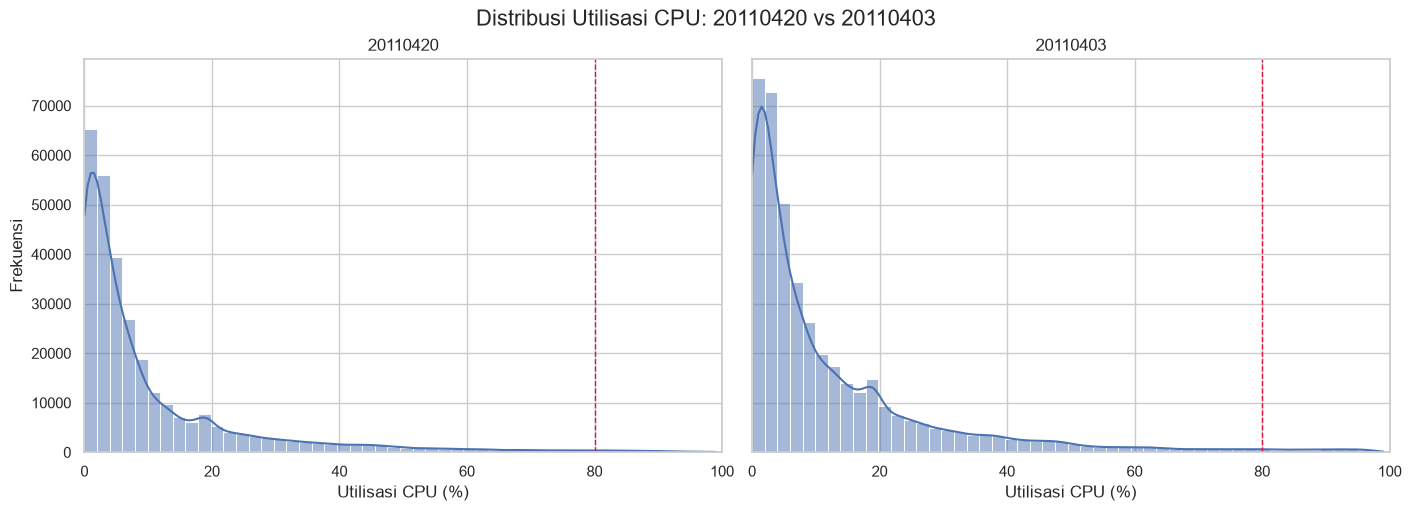

In [10]:
import seaborn as sns

sns.set_theme(style="whitegrid")

comparison_days = ["20110420", "20110403"]
missing_days = [day for day in comparison_days if day not in df_by_day]
if missing_days:
    raise ValueError(f"Folder tanggal tidak ditemukan: {missing_days}")

daily_hist_fig, daily_hist_axes = plt.subplots(
    1, 2, figsize=(14, 5), sharex=True, sharey=True, constrained_layout=True
)

for ax, day in zip(daily_hist_axes, comparison_days):
    cpu_values = df_by_day[day].to_numpy(dtype=float).ravel()
    cpu_values = cpu_values[np.isfinite(cpu_values)] * 100

    sns.histplot(cpu_values, bins=50, kde=True, ax=ax)
    ax.axvline(80, color="crimson", linestyle="--", linewidth=1)
    ax.set_title(day)
    ax.set_xlabel("Utilisasi CPU (%)")
    ax.set_ylabel("Frekuensi")
    ax.set_xlim(0, 100)

daily_hist_fig.suptitle(
    "Distribusi Utilisasi CPU: 20110420 vs 20110403", fontsize=16
)
plt.show()

## Utilisasi CPU berdasarkan waktu

Trace tidak menyimpan timestamp per sampel, sehingga notebook memberi label waktu dengan asumsi sampel pertama berada pada **00:00**, lalu sampel berikutnya setiap 5 menit. Dengan konvensi ini baris ke-5 (dihitung mulai dari 1) adalah **00:20**; 00:05 adalah baris ke-2. Grafik membandingkan rata-rata utilisasi CPU seluruh VM dan persentase VM yang melewati 80% pada setiap waktu.

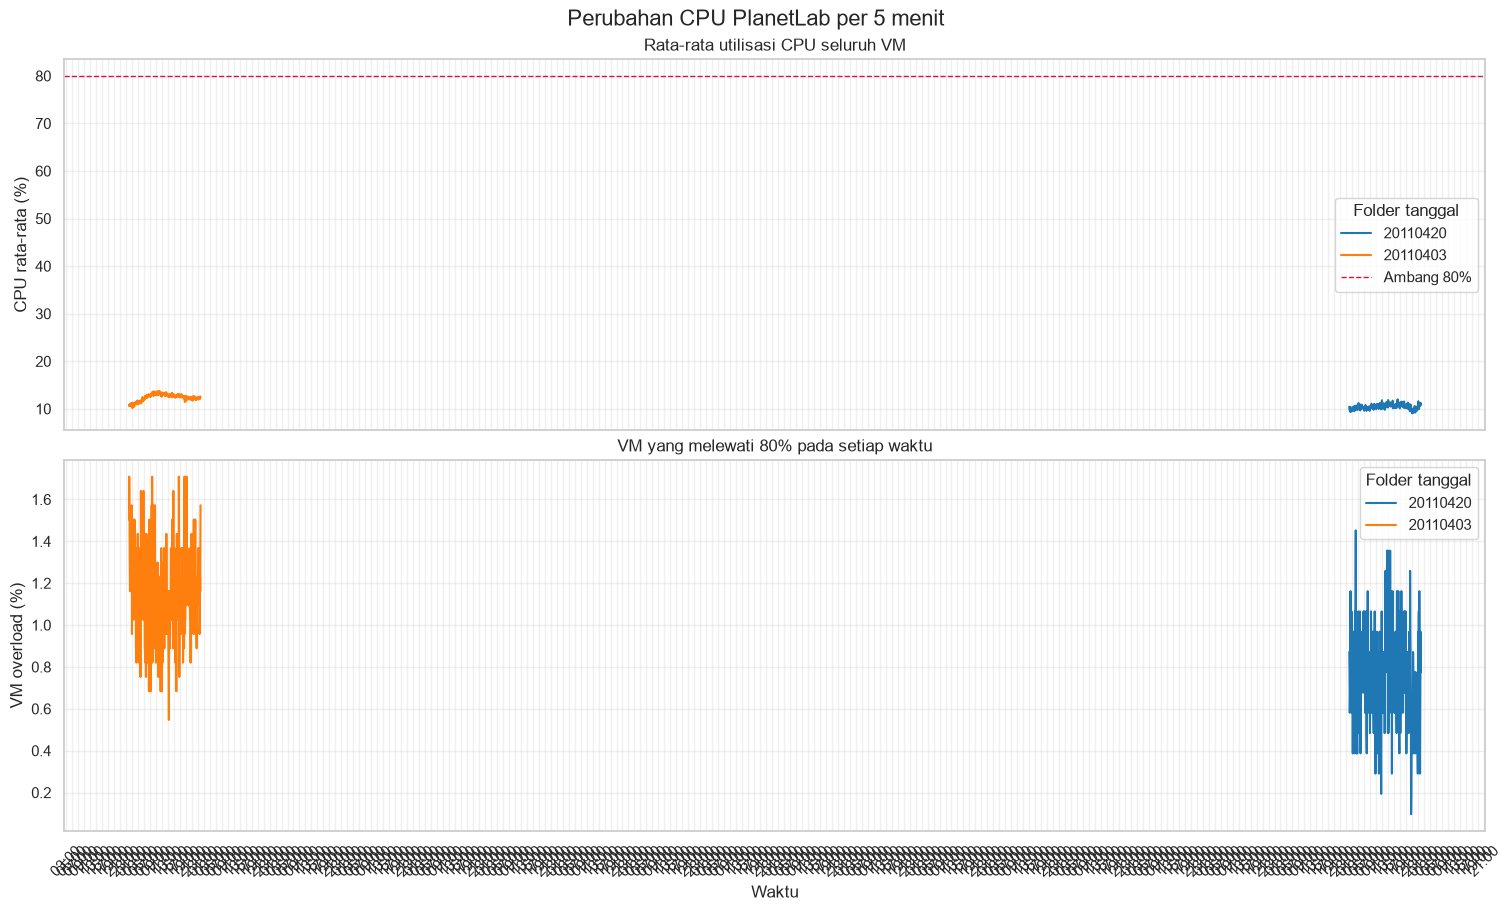

In [11]:
import matplotlib.dates as mdates

time_fig, time_axes = plt.subplots(
    2, 1, figsize=(15, 9), sharex=True, constrained_layout=True
)
time_colors = {"20110420": "tab:blue", "20110403": "tab:orange"}

for day in comparison_days:
    daily_df = df_by_day[day]
    mean_cpu_by_time = daily_df.mean(axis=1) * 100
    overloaded_vm_pct_by_time = (
        (daily_df > CPU_OVERLOAD_THRESHOLD).mean(axis=1) * 100
    )

    time_axes[0].plot(
        daily_df.index, mean_cpu_by_time, label=day, color=time_colors[day]
    )
    time_axes[1].plot(
        daily_df.index,
        overloaded_vm_pct_by_time,
        label=day,
        color=time_colors[day],
    )

time_axes[0].axhline(
    80, color="crimson", linestyle="--", linewidth=1, label="Ambang 80%"
)
time_axes[0].set_title("Rata-rata utilisasi CPU seluruh VM")
time_axes[0].set_ylabel("CPU rata-rata (%)")
time_axes[0].legend(title="Folder tanggal")

time_axes[1].set_title("VM yang melewati 80% pada setiap waktu")
time_axes[1].set_ylabel("VM overload (%)")
time_axes[1].set_xlabel("Waktu")
time_axes[1].legend(title="Folder tanggal")

for ax in time_axes:
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.tick_params(axis="x", rotation=45)

time_fig.suptitle("Perubahan CPU PlanetLab per 5 menit", fontsize=16)
plt.show()